In [ ]:
import gzip, hashlib, json, time, urllib.request, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Arborescence du projet (le notebook peut être lancé depuis notebooks/ ou depuis la racine)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, FIG, RES = ROOT / "data", ROOT / "figures", ROOT / "resultats"
EXT = DATA / "external"
for d in (FIG, RES, EXT):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
rng = np.random.default_rng(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.titleweight": "bold"})
PALETTE = sns.color_palette("tab10", 10)
CHIFFRES = {}  # chiffres clés réutilisés dans le rapport

def savefig(nom):
    plt.savefig(FIG / f"{nom}.png", bbox_inches="tight", facecolor="white")

def pct(x, nd=1):
    return round(100 * float(x), nd)

---
# 3. Présenter et contextualiser les données

## 3.1 Lecture des fichiers IDX

MNIST est distribué en 4 fichiers compressés au format binaire

In [ ]:
FICHIERS = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images":  "t10k-images-idx3-ubyte.gz",
    "test_labels":  "t10k-labels-idx1-ubyte.gz",
}

def lire_idx(chemin):
    # Lit un fichier IDX gzippé et renvoie (nombre magique, dimensions, tableau numpy)
    with gzip.open(chemin, "rb") as f:
        brut = f.read()
    magique = int.from_bytes(brut[:4], "big")
    assert brut[0] == 0 and brut[1] == 0, "en-tête IDX invalide"
    assert brut[2] == 0x08, "type de donnée attendu : unsigned byte"
    ndim = brut[3]
    dims = [int.from_bytes(brut[4 + 4*i: 8 + 4*i], "big") for i in range(ndim)]
    valeurs = np.frombuffer(brut, dtype=np.uint8, offset=4 + 4*ndim)
    assert valeurs.size == np.prod(dims), "taille déclarée ≠ taille lue"
    return magique, dims, valeurs.reshape(dims)

meta, arrays = [], {}
for cle, nom in FICHIERS.items():
    chemin = DATA / nom
    magique, dims, arr = lire_idx(chemin)
    arrays[cle] = arr
    meta.append({"fichier": nom, "nombre magique": magique,
                 "dimensions": " × ".join(map(str, dims)),
                 "taille compressée (Mo)": round(chemin.stat().st_size / 1e6, 2),
                 "MD5": hashlib.md5(chemin.read_bytes()).hexdigest()})

X_train, y_train = arrays["train_images"], arrays["train_labels"]
X_test,  y_test  = arrays["test_images"],  arrays["test_labels"]
meta = pd.DataFrame(meta)
meta.to_csv(RES / "t3_1_fichiers.csv", index=False)
meta

,fichier,nombre magique,dimensions,taille compressée (Mo),MD5
0,train-images-idx3-ubyte.gz,2051,60000 × 28 × 28,9.91,f68b3c2dcbeaaa9fbdd348bbdeb94873
1,train-labels-idx1-ubyte.gz,2049,60000,0.03,d53e105ee54ea40749a09fcbcd1e9432
2,t10k-images-idx3-ubyte.gz,2051,10000 × 28 × 28,1.65,9fb629c4189551a2d022fa330f9573f3
3,t10k-labels-idx1-ubyte.gz,2049,10000,0.00,ec29112dd5afa0611ce80d1b7f02629c


Les nombres magiques 2051 (`0x00000803`, tenseur 3D d'octets) et 2049 (`0x00000801`, vecteur d'octets) correspondent à la spécification officielle.
Les MD5 sont conservés pour la traçabilité (reproductibilité du rapport).

## 3.2 Typologie des variables

In [ ]:
typologie = pd.DataFrame([
    {"variable": "pixel_0 … pixel_783 (784 variables)",
     "rôle": "prédicteurs",
     "type": "quantitative discrète (ordinale)",
     "unité / codage": "niveau de gris, entier de 0 (fond) à 255 (encre)",
     "domaine observé": f"[{X_train.min()} ; {X_train.max()}]"},
    {"variable": "label",
     "rôle": "variable cible",
     "type": "qualitative nominale (10 modalités)",
     "unité / codage": "chiffre représenté (0 à 9)",
     "domaine observé": f"{{{', '.join(map(str, np.unique(y_train)))}}}"},
])
typologie.to_csv(RES / "t3_2_typologie.csv", index=False)

CHIFFRES.update({
    "n_train": int(len(y_train)), "n_test": int(len(y_test)),
    "n_total": int(len(y_train) + len(y_test)),
    "hauteur": int(X_train.shape[1]), "largeur": int(X_train.shape[2]),
    "n_pixels": int(X_train.shape[1] * X_train.shape[2]),
    "part_test_pct": pct(len(y_test) / (len(y_train) + len(y_test))),
})
typologie

,variable,rôle,type,unité / codage,domaine observé
0,pixel_0 … pixel_783 (784 variables),prédicteurs,quantitative discrète (ordinale),"niveau de gris, entier de 0 (fond) à 255 (encre)",[0 ; 255]
1,label,variable cible,qualitative nominale (10 modalités),chiffre représenté (0 à 9),"{0, 1, 2, 3, 4, 5, 6, 7, 8, 9}"


**Contexte de création** (LeCun, Cortes & Burges ; LeCun *et al.*, 1998) :

* **Source** : base *Modified NIST*, construite à partir des *Special Databases* SD-3 (employés du *US Census Bureau*) et SD-1 (lycéens) du **NIST** (*National Institute of Standards and Technology*, Gaithersburg, Maryland).
* **Créateurs** : Yann LeCun, Corinna Cortes et Christopher J. C. Burges (AT&T Bell Labs / AT&T Labs-Research).
* **Période** : formulaires collectés par le NIST au début des années 1990 ; MNIST publiée en 1998.
* **Construction** : chaque chiffre est normalisé dans une boîte de 20 × 20 pixels (rapport d'aspect conservé), l'anti-crénelage produit des niveaux de gris, puis l'image est centrée (centre de masse) dans une grille 28 × 28.
* **Échantillonnage** : 60 000 images d'apprentissage et 10 000 de test, chaque ensemble mélangeant à parts égales SD-3 et SD-1 ; les scripteurs (~250 par ensemble) sont **disjoints** entre apprentissage et test.
* **Unité statistique** : une image d'un chiffre manuscrit isolé.

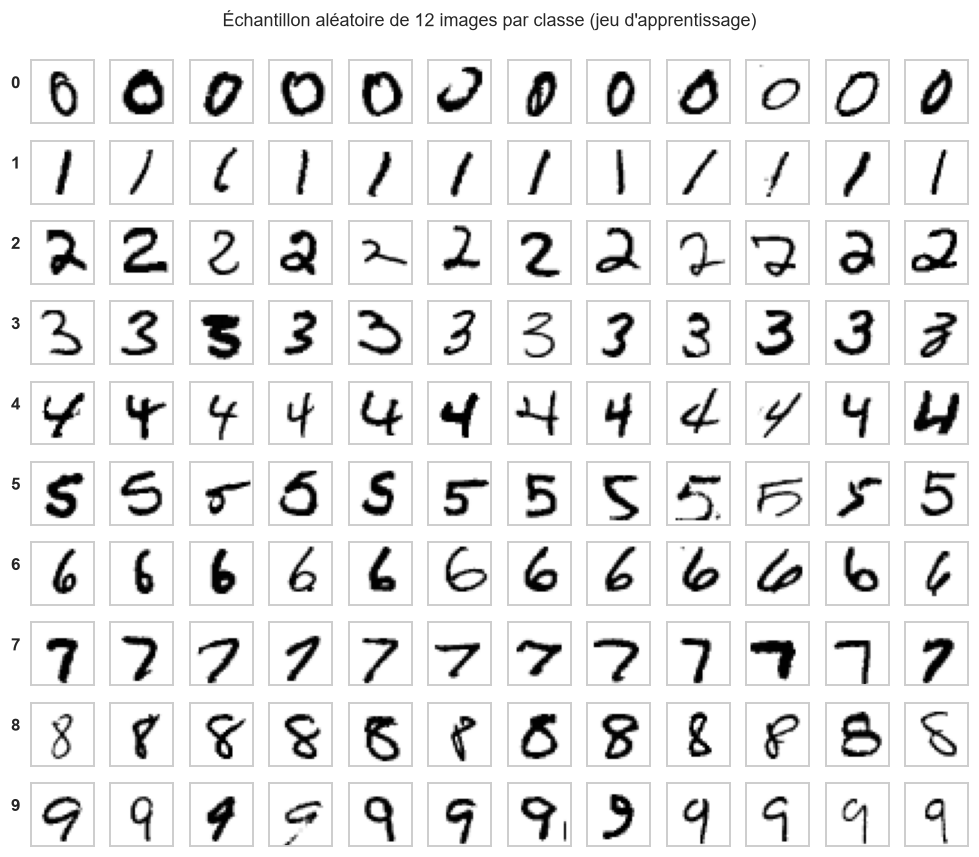

In [ ]:
fig, axes = plt.subplots(10, 12, figsize=(9, 7.8))
for c in range(10):
    idx = rng.choice(np.flatnonzero(y_train == c), 12, replace=False)
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(X_train[i], cmap="gray_r", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(str(c), rotation=0, labelpad=10, fontsize=11, fontweight="bold")
fig.suptitle("Échantillon aléatoire de 12 images par classe (jeu d'apprentissage)", y=0.995)
plt.tight_layout()
savefig("fig3_1_echantillon")
plt.show()

---
# 4. Qualité des données

On contrôle successivement :
1. l'**intégrité** des fichiers et la **complétude** (valeurs manquantes, cohérence images / étiquettes) ;
2. la **validité** des valeurs (domaine des pixels, des étiquettes) ;
3. les **doublons** (internes à chaque jeu, entre apprentissage et test, doublons à étiquettes contradictoires) ;
4. l'**équilibre des classes** et l'homogénéité apprentissage / test ;
5. les **pixels constants** (non informatifs) et le respect du protocole de normalisation (cadrage 20 × 20, centrage).

In [ ]:
# 1-2. Complétude et validité
Xtr = X_train.reshape(len(X_train), -1)
Xte = X_test.reshape(len(X_test), -1)

controle = {
    "images = étiquettes (train)": len(Xtr) == len(y_train),
    "images = étiquettes (test)": len(Xte) == len(y_test),
    "valeurs manquantes": int(pd.isna(Xtr).sum() + pd.isna(Xte).sum()),
    "pixels hors [0 ; 255]": int(((Xtr < 0) | (Xtr > 255)).sum()),
    "étiquettes hors {0..9}": int((~np.isin(np.r_[y_train, y_test], np.arange(10))).sum()),
}
controle

{'images = étiquettes (train)': True,
 'images = étiquettes (test)': True,
 'valeurs manquantes': 0,
 'pixels hors [0 ; 255]': 0,
 'étiquettes hors {0..9}': 0}

In [ ]:
# 3. Doublons exacts : empreinte SHA-1 de chaque image
def empreintes(X):
    return np.array([hashlib.sha1(x.tobytes()).hexdigest() for x in X])

h_tr, h_te = empreintes(Xtr), empreintes(Xte)
dup_tr = len(h_tr) - len(set(h_tr))
dup_te = len(h_te) - len(set(h_te))
commun = set(h_tr) & set(h_te)

# doublons à étiquettes contradictoires (même image, labels différents)
df_h = pd.DataFrame({"h": np.r_[h_tr, h_te], "y": np.r_[y_train, y_test]})
contradictoires = int((df_h.groupby("h")["y"].nunique() > 1).sum())

CHIFFRES.update({"doublons_train": int(dup_tr), "doublons_test": int(dup_te),
                 "doublons_train_test": len(commun),
                 "doublons_contradictoires": contradictoires})
{"doublons internes train": dup_tr, "doublons internes test": dup_te,
 "images communes train/test": len(commun), "doublons à labels contradictoires": contradictoires}

{'doublons internes train': 0,
 'doublons internes test': 0,
 'images communes train/test': 0,
 'doublons à labels contradictoires': 0}

In [ ]:
# 4. Équilibre des classes et homogénéité train / test
eff = pd.DataFrame({"train": np.bincount(y_train, minlength=10),
                    "test": np.bincount(y_test, minlength=10)})
eff.index.name = "classe"
prop = (eff / eff.sum() * 100).round(1)
chi2, p_chi2, ddl, _ = stats.chi2_contingency(eff.T.values)

# indice de déséquilibre : ratio classe majoritaire / minoritaire
ratio = eff["train"].max() / eff["train"].min()
CHIFFRES.update({
    "classe_max_train": int(eff["train"].idxmax()), "pct_max_train": float(prop["train"].max()),
    "classe_min_train": int(eff["train"].idxmin()), "pct_min_train": float(prop["train"].min()),
    "ratio_desequilibre": round(float(ratio), 2),
    "chi2": round(float(chi2), 1), "chi2_ddl": int(ddl), "chi2_p": round(float(p_chi2), 3),
})
prop.rename(columns={"train": "train (%)", "test": "test (%)"}).to_csv(RES / "t4_1_classes_pct.csv")
print(f"Chi² d'homogénéité train/test : {chi2:.1f} (ddl = {ddl}), p = {p_chi2:.3f}")
prop.T

Chi² d'homogénéité train/test : 2.9 (ddl = 9), p = 0.967


classe,0,1,2,3,4,5,6,7,8,9
train,9.9,11.2,9.9,10.2,9.7,9.0,9.9,10.4,9.8,9.9
test,9.8,11.4,10.3,10.1,9.8,8.9,9.6,10.3,9.7,10.1


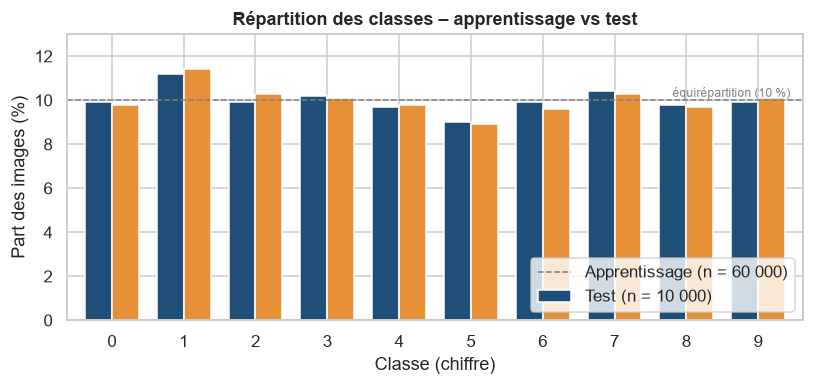

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
prop.plot.bar(ax=ax, color=["#1f4e79", "#e69138"], width=0.75, edgecolor="white")
ax.axhline(10, ls="--", lw=1, color="grey")
ax.text(9.45, 10.15, "équirépartition (10 %)", ha="right", fontsize=8, color="grey")
ax.set_xlabel("Classe (chiffre)"); ax.set_ylabel("Part des images (%)")
ax.set_title("Répartition des classes – apprentissage vs test")
ax.set_ylim(0, 13); ax.tick_params(axis="x", rotation=0)
ax.legend(["Apprentissage (n = 60 000)", "Test (n = 10 000)"], loc="lower right", frameon=True)
plt.tight_layout(); savefig("fig4_1_classes"); plt.show()

In [ ]:
# 5a. Pixels constants (variance nulle) = variables non informatives
var_tr = Xtr.var(axis=0)
const_tr = var_tr == 0
toujours_zero = (Xtr.max(axis=0) == 0)
CHIFFRES.update({"pixels_constants": int(const_tr.sum()),
                 "pixels_constants_pct": pct(const_tr.mean()),
                 "pixels_quasi_constants": int(((Xtr > 0).mean(axis=0) < 0.001).sum())})

# 5b. Protocole de normalisation : boîte englobante et centre de masse
def boite_et_centre(X):
    enc = X > 0
    lignes, cols = enc.any(axis=2), enc.any(axis=1)
    h = lignes.shape[1] - np.argmax(lignes[:, ::-1], 1) - np.argmax(lignes, 1)
    w = cols.shape[1] - np.argmax(cols[:, ::-1], 1) - np.argmax(cols, 1)
    m = X.sum(axis=(1, 2)).astype(float)
    grille = np.arange(28)
    cy = (X.sum(axis=2) * grille).sum(1) / m
    cx = (X.sum(axis=1) * grille).sum(1) / m
    return h, w, cy, cx

h, w, cy, cx = boite_et_centre(X_train)
geo = pd.DataFrame({"hauteur": h, "largeur": w, "centre_y": cy, "centre_x": cx, "label": y_train})
CHIFFRES.update({
    "pct_boite_20": pct(((h <= 20) & (w <= 20)).mean()),
    "pct_hauteur_20": pct((h == 20).mean()),
    "centre_y_moy": round(float(cy.mean()), 2), "centre_x_moy": round(float(cx.mean()), 2),
    "centre_ecart_max": round(float(np.max(np.abs(np.c_[cy, cx] - np.c_[cy, cx].mean(0)))), 2),
})
geo[["hauteur", "largeur", "centre_y", "centre_x"]].describe().round(2)

,hauteur,largeur,centre_y,centre_x
count,60000.00,60000.00,60000.00,60000.00
mean,19.74,15.68,14.00,14.01
std,0.99,3.86,0.29,0.29
min,9.00,2.00,13.48,13.49
25%,20.00,14.00,13.74,13.75
50%,20.00,16.00,13.99,14.01
75%,20.00,19.00,14.25,14.26
max,20.00,20.00,14.50,14.50


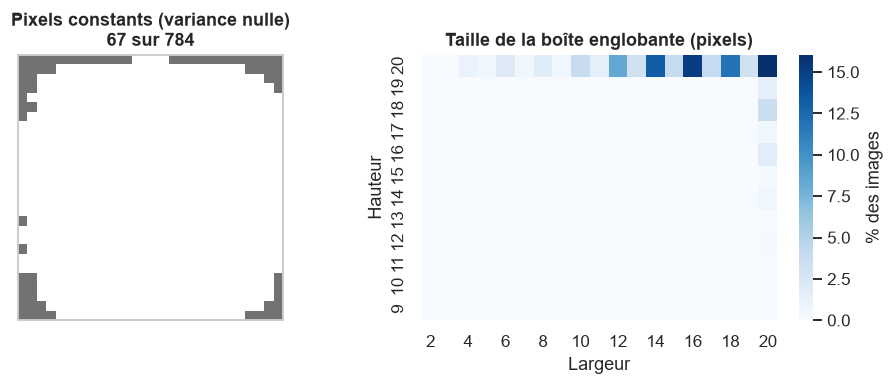

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
im = axes[0].imshow(const_tr.reshape(28, 28), cmap="Greys", vmin=0, vmax=1.6)
axes[0].set_title(f"Pixels constants (variance nulle)\n{const_tr.sum()} sur 784")
axes[0].set_xticks([]); axes[0].set_yticks([])

hw = pd.crosstab(geo["hauteur"], geo["largeur"], normalize=True) * 100
sns.heatmap(hw.loc[::-1], ax=axes[1], cmap="Blues", cbar_kws={"label": "% des images"})
axes[1].set_title("Taille de la boîte englobante (pixels)")
axes[1].set_xlabel("Largeur"); axes[1].set_ylabel("Hauteur")
plt.tight_layout(); savefig("fig4_2_qualite_pixels"); plt.show()

In [ ]:
# Synthèse qualité
qualite = pd.DataFrame([
    ("Intégrité", "En-têtes IDX (nombre magique, tailles)", "conforme", "aucune"),
    ("Complétude", "Valeurs manquantes", f"{controle['valeurs manquantes']}", "aucune"),
    ("Validité", "Pixels ∈ [0 ; 255], labels ∈ {0..9}",
     "conforme" if controle["pixels hors [0 ; 255]"] == 0 and controle["étiquettes hors {0..9}"] == 0 else "anomalie", "aucune"),
    ("Unicité", "Doublons exacts (train / test / croisés)",
     f"{dup_tr} / {dup_te} / {len(commun)}", "aucune"),
    ("Cohérence", "Même image avec labels différents", f"{contradictoires}", "aucune"),
    ("Représentativité", "Ratio classe max / min (train)", f"{ratio:.2f}", "pas de rééquilibrage"),
    ("Homogénéité", "Distribution des classes train vs test (χ²)", f"p = {p_chi2:.2f}", "aucune"),
    ("Pertinence", "Pixels de variance nulle", f"{const_tr.sum()} ({pct(const_tr.mean())} %)", "à retirer pour la modélisation"),
    ("Conformité", "Chiffre inscrit dans une boîte ≤ 20 × 20", f"{pct(((h <= 20) & (w <= 20)).mean())} %", "aucune"),
], columns=["dimension", "contrôle", "résultat", "action"])
qualite.to_csv(RES / "t4_2_synthese_qualite.csv", index=False)
qualite

,dimension,contrôle,résultat,action
0,Intégrité,"En-têtes IDX (nombre magique, tailles)",conforme,aucune
1,Complétude,Valeurs manquantes,0,aucune
2,Validité,"Pixels ∈ [0 ; 255], labels ∈ {0..9}",conforme,aucune
3,Unicité,Doublons exacts (train / test / croisés),0 / 0 / 0,aucune
4,Cohérence,Même image avec labels différents,0,aucune
5,Représentativité,Ratio classe max / min (train),1.24,pas de rééquilibrage
6,Homogénéité,Distribution des classes train vs test (χ²),p = 0.97,aucune
7,Pertinence,Pixels de variance nulle,67 (8.5 %),à retirer pour la modélisation
8,Conformité,Chiffre inscrit dans une boîte ≤ 20 × 20,100.0 %,aucune


---
# 5. Explorer les données

## 5.i Descripteurs statistiques

Les 784 pixels pris un par un ont peu de sens ; on résume chaque image par des **descripteurs interprétables** :

* **encre totale** : somme des niveaux de gris / 255 (≈ nombre de pixels « pleins ») ;
* **couverture** : part des 784 pixels non nuls (%) ;
* **intensité moyenne de l'encre** : moyenne des pixels non nuls ;
* **hauteur / largeur** de la boîte englobante.

In [ ]:
desc = pd.DataFrame({
    "label": y_train,
    "encre": Xtr.sum(axis=1) / 255,
    "couverture_pct": (Xtr > 0).mean(axis=1) * 100,
    "intensite_encre": Xtr.sum(axis=1) / np.maximum((Xtr > 0).sum(axis=1), 1),
    "hauteur": h, "largeur": w,
})

# Distribution globale des niveaux de gris
pix = Xtr.ravel()
CHIFFRES.update({
    "pct_pixels_zero": pct((pix == 0).mean()),
    "pct_pixels_255": pct((pix == 255).mean()),
    "pct_pixels_gris": pct(((pix > 0) & (pix < 255)).mean()),
    "pct_pixels_sup_128_parmi_encre": pct((pix[pix > 0] >= 128).mean()),
    "couverture_moy": round(float(desc["couverture_pct"].mean()), 1),
    "couverture_mediane": round(float(desc["couverture_pct"].median()), 1),
    "intensite_moy": round(float(desc["intensite_encre"].mean()), 1),
})

global_desc = desc[["encre", "couverture_pct", "intensite_encre", "hauteur", "largeur"]] \
    .describe(percentiles=[.25, .5, .75]).T.round(1)
global_desc.to_csv(RES / "t5_1_descripteurs_globaux.csv")
global_desc

,count,mean,std,min,25%,50%,75%,max
encre,60000.0,102.4,33.9,19.9,77.9,99.9,123.8,311.7
couverture_pct,60000.0,19.1,5.3,4.3,15.6,19.1,22.7,44.8
intensite_encre,60000.0,172.4,17.1,103.4,161.2,172.2,183.2,255.0
hauteur,60000.0,19.7,1.0,9.0,20.0,20.0,20.0,20.0
largeur,60000.0,15.7,3.9,2.0,14.0,16.0,19.0,20.0


In [ ]:
par_classe = desc.groupby("label").agg(
    part_pct=("label", lambda s: len(s) / len(desc) * 100),
    encre_moy=("encre", "mean"), encre_et=("encre", "std"),
    couverture_med=("couverture_pct", "median"),
    intensite_moy=("intensite_encre", "mean"),
    largeur_moy=("largeur", "mean"), hauteur_moy=("hauteur", "mean"),
).round(1)
par_classe.to_csv(RES / "t5_2_descripteurs_par_classe.csv")

# Test de Kruskal-Wallis : la quantité d'encre dépend-elle de la classe ?
kw = stats.kruskal(*[desc.loc[desc.label == c, "encre"] for c in range(10)])
CHIFFRES.update({
    "classe_plus_encre": int(par_classe["encre_moy"].idxmax()),
    "encre_max": float(par_classe["encre_moy"].max()),
    "classe_moins_encre": int(par_classe["encre_moy"].idxmin()),
    "encre_min": float(par_classe["encre_moy"].min()),
    "largeur_1": float(par_classe.loc[1, "largeur_moy"]),
    "largeur_0": float(par_classe.loc[0, "largeur_moy"]),
    "kruskal_H": round(float(kw.statistic), 0),
})
print(f"Kruskal-Wallis (encre ~ classe) : H = {kw.statistic:.0f}, p = {kw.pvalue:.1e}")
par_classe

Kruskal-Wallis (encre ~ classe) : H = 20964, p = 0.0e+00


,part_pct,encre_moy,encre_et,couverture_med,intensite_moy,largeur_moy,hauteur_moy
label,,,,,,,
0,9.9,135.9,33.0,24.5,178.8,18.0,19.6
1,11.2,59.6,17.2,10.6,175.3,9.3,20.0
2,9.9,116.8,29.8,21.4,174.7,18.3,19.3
3,10.2,111.0,29.6,20.8,171.4,16.5,19.9
4,9.7,95.2,25.0,17.8,169.3,16.4,19.9
5,9.0,100.9,29.2,19.3,166.8,18.0,19.0
6,9.9,107.6,29.3,19.8,173.1,15.2,19.9
7,10.4,89.8,24.0,16.5,172.5,16.0,19.9
8,9.8,117.7,30.3,21.8,171.5,15.8,19.9


## 5.ii Visualisations

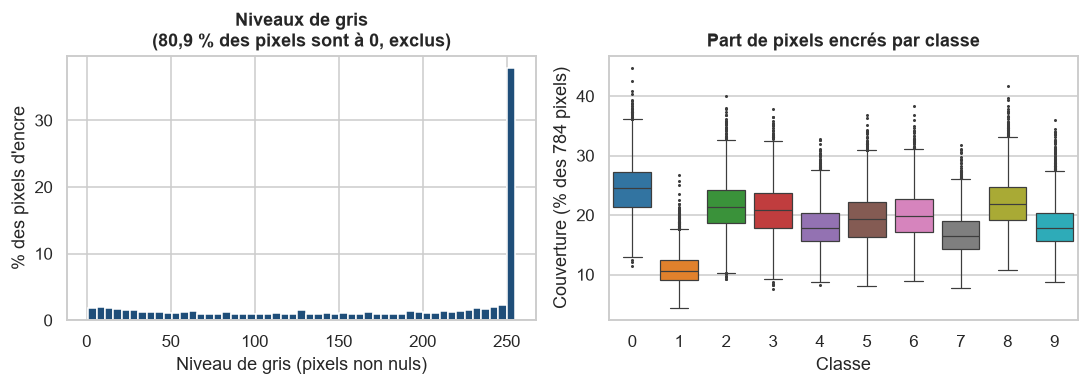

In [ ]:
# Distribution des niveaux de gris (pixels non nuls) en %
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
encre = pix[pix > 0]
poids = np.full(encre.shape, 100 / encre.size)
axes[0].hist(encre, bins=51, weights=poids, color="#1f4e79")
axes[0].set_xlabel("Niveau de gris (pixels non nuls)"); axes[0].set_ylabel("% des pixels d'encre")
axes[0].set_title(f"Niveaux de gris\n({str(CHIFFRES['pct_pixels_zero']).replace('.', ',')} % des pixels sont à 0, exclus)")

ordre = par_classe["encre_moy"].sort_values().index
sns.boxplot(data=desc, x="label", y="couverture_pct", ax=axes[1], hue="label",
            palette=PALETTE, legend=False, fliersize=1, linewidth=0.8)
axes[1].set_xlabel("Classe"); axes[1].set_ylabel("Couverture (% des 784 pixels)")
axes[1].set_title("Part de pixels encrés par classe")
plt.tight_layout(); savefig("fig5_1_distributions"); plt.show()

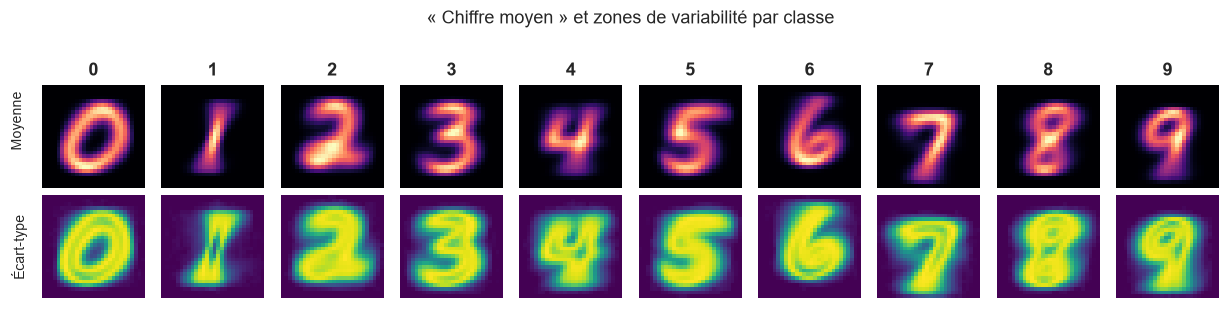

In [ ]:
# Image moyenne et image d'écart-type par classe
moy = np.stack([X_train[y_train == c].mean(0) for c in range(10)])
et  = np.stack([X_train[y_train == c].std(0)  for c in range(10)])
fig, axes = plt.subplots(2, 10, figsize=(11, 2.8))
for c in range(10):
    axes[0, c].imshow(moy[c], cmap="magma"); axes[0, c].set_title(str(c))
    axes[1, c].imshow(et[c], cmap="viridis")
    for a in axes[:, c]: a.axis("off")
fig.text(-0.012, 0.66, "Moyenne", rotation=90, va="center", fontsize=9)
fig.text(-0.012, 0.25, "Écart-type", rotation=90, va="center", fontsize=9)
fig.suptitle("« Chiffre moyen » et zones de variabilité par classe", y=1.02)
plt.tight_layout(); savefig("fig5_2_moyennes_classes"); plt.show()

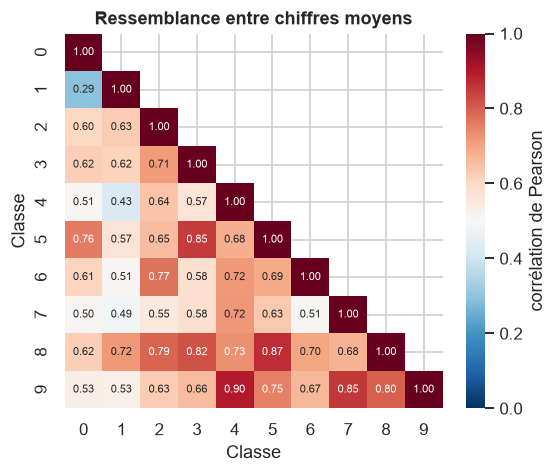

4  9    0.90
5  8    0.87
7  9    0.85
3  5    0.85
   8    0.82
dtype: float64

In [ ]:
# Similarité entre classes : corrélation des images moyennes
corr = np.corrcoef(moy.reshape(10, -1))
corr_df = pd.DataFrame(corr, index=range(10), columns=range(10))
masque = np.triu(np.ones_like(corr, bool), k=1)
fig, ax = plt.subplots(figsize=(5.2, 4.4))
sns.heatmap(corr_df, mask=masque, annot=True, fmt=".2f", cmap="RdBu_r", vmin=0, vmax=1,
            annot_kws={"size": 7}, ax=ax, cbar_kws={"label": "corrélation de Pearson"})
ax.set_title("Ressemblance entre chiffres moyens"); ax.set_xlabel("Classe"); ax.set_ylabel("Classe")
plt.tight_layout(); savefig("fig5_3_correlation_classes"); plt.show()

paires = corr_df.where(~np.tril(np.ones_like(corr, bool))).stack().dropna().sort_values(ascending=False)
CHIFFRES["paires_proches"] = [f"{a}-{b} ({v:.2f})" for (a, b), v in paires.head(3).items()]
CHIFFRES["paire_eloignee"] = "{}-{} ({:.2f})".format(*paires.index[-1], paires.iloc[-1])
paires.head(5).round(2)

In [ ]:
# Réduction de dimension : ACP (sur les pixels non constants, normalisés sur [0,1])
utiles = ~const_tr
Xn = Xtr[:, utiles] / 255.0
acp = PCA(random_state=SEED).fit(Xn)
cum = np.cumsum(acp.explained_variance_ratio_) * 100
n80, n90, n95 = (int(np.searchsorted(cum, s) + 1) for s in (80, 90, 95))
CHIFFRES.update({"acp_n80": n80, "acp_n90": n90, "acp_n95": n95,
                 "acp_cp1_pct": pct(acp.explained_variance_ratio_[0]),
                 "acp_cp2_pct": pct(acp.explained_variance_ratio_[1]),
                 "acp_2cp_pct": round(float(cum[1]), 1)})

# Échantillon stratifié de 5 000 images pour les projections 2D
ech = np.concatenate([rng.choice(np.flatnonzero(y_train == c), 500, replace=False) for c in range(10)])
proj_acp = acp.transform(Xn[ech])[:, :2]
t0 = time.time()
proj_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED) \
    .fit_transform(PCA(50, random_state=SEED).fit_transform(Xn[ech]))
print(f"t-SNE : {time.time() - t0:.0f} s ; composantes pour 80/90/95 % de variance : {n80}/{n90}/{n95}")

t-SNE : 21 s ; composantes pour 80/90/95 % de variance : 44/87/154


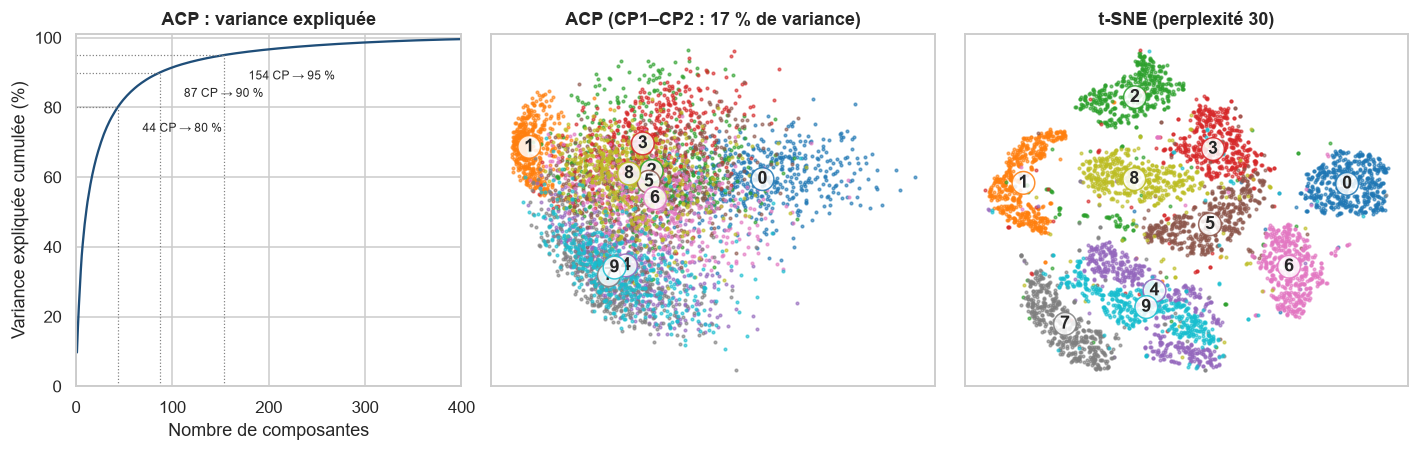

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.15, 1.15]})
axes[0].plot(np.arange(1, len(cum) + 1), cum, color="#1f4e79")
for n, s in ((n80, 80), (n90, 90), (n95, 95)):
    axes[0].plot([n, n], [0, s], ls=":", c="grey", lw=0.8); axes[0].plot([0, n], [s, s], ls=":", c="grey", lw=0.8)
    axes[0].annotate(f"{n} CP → {s} %", (n, s), xytext=(n + 25, s - 7), fontsize=8)
axes[0].set_xlim(0, 400); axes[0].set_ylim(0, 101)
axes[0].set_xlabel("Nombre de composantes"); axes[0].set_ylabel("Variance expliquée cumulée (%)")
axes[0].set_title("ACP : variance expliquée")

for ax, P, titre in ((axes[1], proj_acp, f"ACP (CP1–CP2 : {cum[1]:.0f} % de variance)"),
                     (axes[2], proj_tsne, "t-SNE (perplexité 30)")):
    for c in range(10):
        m = y_train[ech] == c
        ax.scatter(P[m, 0], P[m, 1], s=3, alpha=0.6, color=PALETTE[c], label=str(c))
        cx_, cy_ = np.median(P[m], axis=0)
        ax.text(cx_, cy_, str(c), fontsize=12, weight="bold", ha="center", va="center",
                bbox=dict(boxstyle="circle,pad=0.15", fc="white", ec=PALETTE[c], alpha=0.85))
    ax.set_title(titre); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); savefig("fig5_4_acp_tsne"); plt.show()

## 5.iii Dataviz originale : « empreinte radiale » des chiffres

*Radial line graph* : pour chaque image, on calcule la répartition de l'encre selon l'**angle** autour du centre de masse (36 secteurs de 10°), puis on moyenne par classe.
Chaque chiffre obtient ainsi une signature polaire : le « 1 » est un trait vertical (deux lobes à 90° et 270°), le « 0 » un anneau quasi circulaire, le « 7 » concentre son encre en haut à droite, etc.

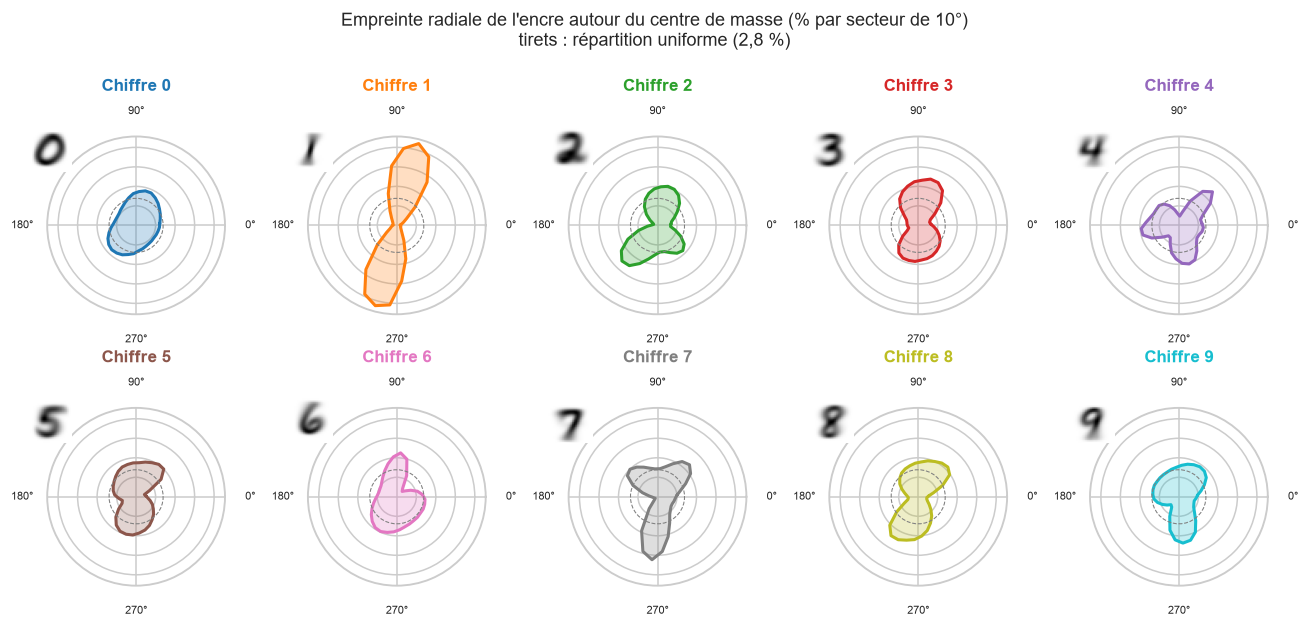

In [ ]:
N_SECT = 36
yy, xx = np.mgrid[0:28, 0:28]

def profil_radial(X, cy, cx):
    # part de l'encre (%) dans chaque secteur angulaire autour du centre de masse
    ang = np.degrees(np.arctan2(-(yy[None] - cy[:, None, None]), xx[None] - cx[:, None, None])) % 360
    sect = (ang // (360 / N_SECT)).astype(int).reshape(len(X), -1)
    poids = X.reshape(len(X), -1).astype(float)
    prof = np.zeros((len(X), N_SECT))
    for s in range(N_SECT):
        prof[:, s] = (poids * (sect == s)).sum(1)
    return prof / prof.sum(1, keepdims=True) * 100

profils = np.stack([profil_radial(X_train[y_train == c][:3000], cy[y_train == c][:3000],
                                  cx[y_train == c][:3000]).mean(0) for c in range(10)])
pd.DataFrame(profils.round(2), index=range(10)).to_csv(RES / "t5_3_profils_radiaux_pct.csv")

theta = np.radians(np.arange(N_SECT) * 360 / N_SECT + 360 / N_SECT / 2)
theta_c = np.r_[theta, theta[0]]
fig, axes = plt.subplots(2, 5, figsize=(12, 5.6), subplot_kw={"projection": "polar"})
for c, ax in enumerate(axes.ravel()):
    r = np.r_[profils[c], profils[c][0]]
    ax.fill(theta_c, r, color=PALETTE[c], alpha=0.25)
    ax.plot(theta_c, r, color=PALETTE[c], lw=2)
    ax.plot(theta_c, np.full_like(theta_c, 100 / N_SECT), ls="--", lw=0.7, color="grey")
    ax.set_ylim(0, profils.max() * 1.05)
    ax.set_yticklabels([]); ax.set_xticks(np.radians([0, 90, 180, 270]))
    ax.set_xticklabels(["0°", "90°", "180°", "270°"], fontsize=7)
    ax.set_title(f"Chiffre {c}", pad=10, fontsize=11, color=PALETTE[c])
    # vignette du chiffre moyen au centre
    ins = ax.inset_axes([-0.12, 0.80, 0.26, 0.26]); ins.imshow(moy[c], cmap="gray_r"); ins.axis("off")
fig.suptitle("Empreinte radiale de l'encre autour du centre de masse (% par secteur de 10°)\n"
             "tirets : répartition uniforme (2,8 %)", y=1.0)
plt.tight_layout(); savefig("fig5_5_empreinte_radiale"); plt.show()

anis = (profils.max(1) / profils.min(1))
CHIFFRES["classe_plus_isotrope"] = int(anis.argmin())
CHIFFRES["classe_plus_anisotrope"] = int(anis.argmax())

## 5.iv Carte

MNIST ne contient **aucune variable géographique**. Conformément au sujet, on télécharge des données externes en lien avec la problématique :
les fonds de carte *Natural Earth* (domaine public) et les coordonnées des lieux où les données ont été **collectées, construites** et où l'article étudié a été **produit**.
La carte retrace ainsi la « chaîne de production » du jeu de données jusqu'à l'article de Rana *et al.* (2023).

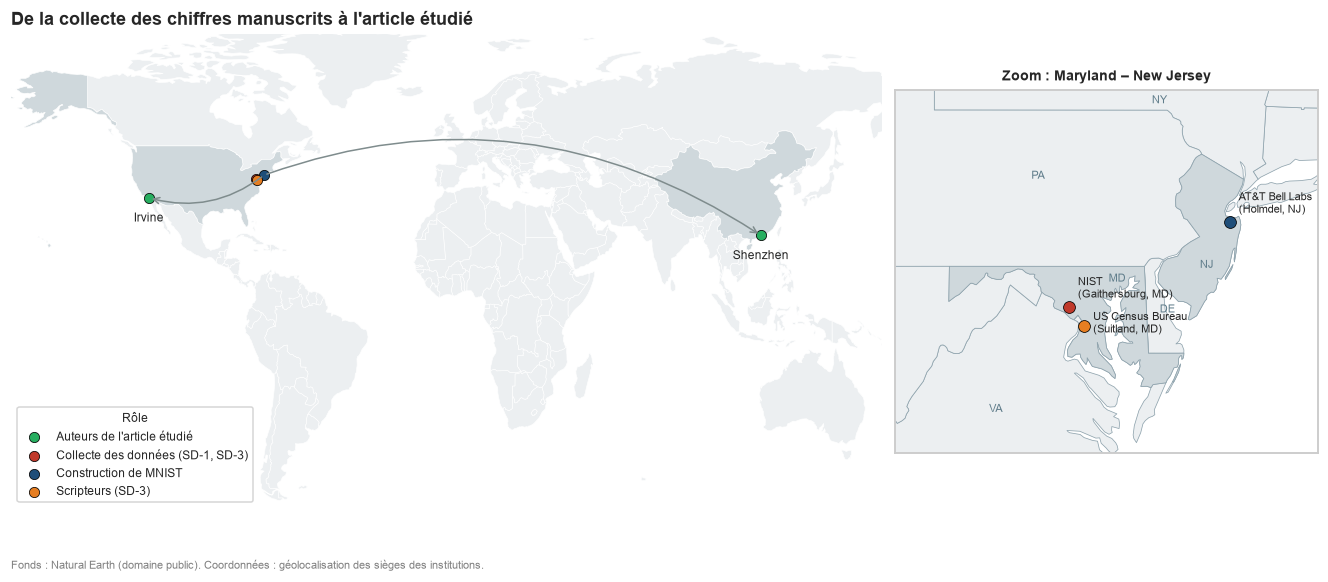

In [ ]:
import geopandas as gpd

NE = {
    "pays": "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip",
    "etats": "https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_1_states_provinces.zip",
}
def charger_ne(cle):
    cible = EXT / Path(NE[cle]).name
    if not cible.exists():
        req = urllib.request.Request(NE[cle], headers={"User-Agent": "Mozilla/5.0 (SAE503)"})
        cible.write_bytes(urllib.request.urlopen(req, timeout=60).read())
    return gpd.read_file(cible)

monde = charger_ne("pays")
etats = charger_ne("etats")
etats_us = etats[etats["adm0_a3"] == "USA"]

lieux = pd.DataFrame([
    ("NIST (Gaithersburg, MD)", 39.1336, -77.2167, "Collecte des données (SD-1, SD-3)"),
    ("US Census Bureau (Suitland, MD)", 38.8468, -76.9283, "Scripteurs (SD-3)"),
    ("AT&T Bell Labs (Holmdel, NJ)", 40.3707, -74.1720, "Construction de MNIST"),
    ("Westcliff University (Irvine, CA)", 33.6846, -117.8265, "Auteurs de l'article étudié"),
    ("SIAT – CAS (Shenzhen, Chine)", 22.5964, 113.9939, "Auteurs de l'article étudié"),
], columns=["lieu", "lat", "lon", "rôle"])
lieux = gpd.GeoDataFrame(lieux, geometry=gpd.points_from_xy(lieux.lon, lieux.lat), crs="EPSG:4326")
lieux.drop(columns="geometry").to_csv(RES / "t5_4_lieux_carte.csv", index=False)

COUL = {"Collecte des données (SD-1, SD-3)": "#c0392b", "Scripteurs (SD-3)": "#e67e22",
        "Construction de MNIST": "#1f4e79", "Auteurs de l'article étudié": "#27ae60"}

fig = plt.figure(figsize=(12, 5.2))
ax = fig.add_axes([0.0, 0.0, 0.66, 1.0])
monde.plot(ax=ax, color="#eceff1", edgecolor="white", lw=0.4)
monde[monde["ADM0_A3"].isin(["USA", "CHN"])].plot(ax=ax, color="#cfd8dc", edgecolor="white", lw=0.4)
for role, g in lieux.groupby("rôle"):
    g.plot(ax=ax, color=COUL[role], markersize=45, edgecolor="black", lw=0.5, label=role, zorder=3)
# flux : données NIST → MNIST → article
for dst in (3, 4):
    ax.annotate("", xy=(lieux.lon[dst], lieux.lat[dst]), xytext=(lieux.lon[2], lieux.lat[2]),
                arrowprops=dict(arrowstyle="->", color="#7f8c8d", lw=1, connectionstyle="arc3,rad=-0.25"))
ax.text(lieux.lon[4], lieux.lat[4] - 7, "Shenzhen", ha="center", fontsize=8)
ax.text(lieux.lon[3], lieux.lat[3] - 7, "Irvine", ha="center", fontsize=8)
ax.set_xlim(-170, 160); ax.set_ylim(-58, 82); ax.axis("off")
ax.legend(loc="lower left", fontsize=8, title="Rôle", title_fontsize=8, frameon=True)
ax.set_title("De la collecte des chiffres manuscrits à l'article étudié", loc="left")

# Zoom côte Est des États-Unis
ax2 = fig.add_axes([0.67, 0.08, 0.32, 0.84])
etats_us.plot(ax=ax2, color="#eceff1", edgecolor="#90a4ae", lw=0.5)
etats_us[etats_us["postal"].isin(["MD", "NJ"])].plot(ax=ax2, color="#cfd8dc", edgecolor="#90a4ae", lw=0.5)
est = lieux.iloc[:3]
for _, r in est.iterrows():
    ax2.scatter(r.lon, r.lat, s=60, color=COUL[r["rôle"]], edgecolor="black", lw=0.5, zorder=3)
    ax2.annotate(r.lieu.replace(" (", "\n("), (r.lon, r.lat), xytext=(6, -4 if "Census" in r.lieu else 6),
                 textcoords="offset points", fontsize=7.5)
for code_, (x_, y_) in {"PA": (-77.8, 41.0), "VA": (-78.6, 37.6), "NJ": (-74.6, 39.7),
                         "MD": (-76.3, 39.5), "DE": (-75.35, 39.05), "NY": (-75.5, 42.1)}.items():
    ax2.text(x_, y_, code_, fontsize=7, color="#607d8b", ha="center")
ax2.set_xlim(-80.5, -72.5); ax2.set_ylim(37.0, 42.3); ax2.set_xticks([]); ax2.set_yticks([])
ax2.set_xlabel(""); ax2.set_ylabel("")
ax2.set_title("Zoom : Maryland – New Jersey", fontsize=9)
fig.text(0.0, -0.02, "Fonds : Natural Earth (domaine public). Coordonnées : géolocalisation des sièges des institutions.",
         fontsize=7, color="grey")
savefig("fig5_6_carte"); plt.show()

In [ ]:
CHIFFRES["date_execution"] = time.strftime("%Y-%m-%d")
(RES / "chiffres_cles.json").write_text(json.dumps(CHIFFRES, indent=2, ensure_ascii=False), encoding="utf-8")
CHIFFRES

{'n_train': 60000,
 'n_test': 10000,
 'n_total': 70000,
 'hauteur': 28,
 'largeur': 28,
 'n_pixels': 784,
 'part_test_pct': 14.3,
 'doublons_train': 0,
 'doublons_test': 0,
 'doublons_train_test': 0,
 'doublons_contradictoires': 0,
 'classe_max_train': 1,
 'pct_max_train': 11.2,
 'classe_min_train': 5,
 'pct_min_train': 9.0,
 'ratio_desequilibre': 1.24,
 'chi2': 2.9,
 'chi2_ddl': 9,
 'chi2_p': 0.967,
 'pixels_constants': 67,
 'pixels_constants_pct': 8.5,
 'pixels_quasi_constants': 189,
 'pct_boite_20': 100.0,
 'pct_hauteur_20': 91.1,
 'centre_y_moy': 14.0,
 'centre_x_moy': 14.01,
 'centre_ecart_max': 0.52,
 'pct_pixels_zero': 80.9,
 'pct_pixels_255': 0.7,
 'pct_pixels_gris': 18.5,
 'pct_pixels_sup_128_parmi_encre': 69.2,
 'couverture_moy': 19.1,
 'couverture_mediane': 19.1,
 'intensite_moy': 172.4,
 'classe_plus_encre': 0,
 'encre_max': 135.9,
 'classe_moins_encre': 1,
 'encre_min': 59.6,
 'largeur_1': 9.3,
 'largeur_0': 18.0,
 'kruskal_H': 20964.0,
 'paires_proches': ['4-9 (0.90)', '5